# P8.12 — Butterworth analógico passa-baixas em forma racional

*IIR · protótipo analógico · Butterworth · forma racional*

> Notebook gerado de `content/p8_12.py`, a mesma fonte da aplicação DSP Filter Lab e do relatório PDF. Para alterar o texto, edite o conteúdo e rode `tools/run_notebook.sh p8_12`.

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Enunciado original

> *Design an analog Butterworth lowpass filter that has a 0.25 dB or better ripple at 500 rad/sec and at least 50 dB of attenuation at 2000 rad/sec. Determine the system function in a rational function form. Plot the magnitude response, the log-magnitude response in dB, the phase response, and the impulse response of the filter.*

Fonte: DTA §2.2 item 9 e §4 (Resolução P8.12); Ingle & Proakis, p. 465.

## 2. O que está sendo pedido


Projetar um **filtro analógico passa-baixas de Butterworth** que:

- perca **no máximo 0.25 dB** até $\Omega_p = 500$ rad/s;
- atenue **pelo menos 50 dB** a partir de $\Omega_s = 2000$ rad/s.

O resultado deve ser dado como **função racional** $H_a(s) = B(s)/A(s)$. São pedidos quatro gráficos: magnitude, magnitude em dB, **fase** e resposta ao impulso.

## 3. Dados e especificações

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\Omega_p$ | 500 rad/s | ■ Dado do enunciado | borda de passagem |
| $R_p$ | 0.25 dB | ■ Dado do enunciado | perda máxima até $\Omega_p$ |
| $\Omega_s$ | 2000 rad/s | ■ Dado do enunciado | borda de rejeição |
| $A_s$ | 50 dB | ■ Dado do enunciado | atenuação mínima a partir de $\Omega_s$ |
| Forma | racional | ■ Dado do enunciado | $B(s)/A(s)$ |


As frequências já estão em rad/s, então as fórmulas se aplicam sem conversão.

## 4. Fundamentação teórica


**Butterworth (maximamente plano):** $|H_a(j\Omega)|^2 = 1/[1 + (\Omega/\Omega_c)^{2N}]$. A magnitude é monotônica (sem ondulações), vale $-3$ dB em $\Omega_c$ e decai $20N$ dB por década.

**Ordem e corte.** Impondo $R_p$ em $\Omega_p$ e $A_s$ em $\Omega_s$ e eliminando $\Omega_c$, obtém-se a ordem mínima. Como $N$ é arredondado para cima, sobra folga. O livro escolhe $\Omega_c$ para atender $R_p$ **exatamente**, e a folga vai toda para a rejeição.

**Polos.** $N$ pontos igualmente espaçados de $180°/N$ no semicírculo esquerdo de raio $\Omega_c$. Isso garante um filtro estável.

**Forma racional.** $H_a(s) = \Omega_c^N/\prod_k(s - p_k)$. Multiplicando os fatores, obtém-se um denominador mônico de grau $N$ com coeficientes reais e positivos (polinômio de Hurwitz).


#### Aprofundamento: De onde vem a fórmula da ordem?


De $1 + (\Omega_p/\Omega_c)^{2N} = 10^{R_p/10}$ e $1 + (\Omega_s/\Omega_c)^{2N} = 10^{A_s/10}$. Dividindo uma pela outra, $(\Omega_p/\Omega_s)^{2N} = (10^{R_p/10}-1)/(10^{A_s/10}-1)$. Tomando o logaritmo e isolando $N$, chega-se à fórmula. Arredonda-se para cima porque $N$ é inteiro.


#### Aprofundamento: Como ler a fase?


A fase total vai de 0 a $-N\pi/2 = -6\pi/2$ quando $\Omega \to \infty$. O gráfico mostra a **fase principal**, em $(-\pi, \pi]$, como a função `freqs_m` do livro. Os saltos de $2\pi$ são só a passagem por $\pm\pi$, não descontinuidades físicas.

## 5. Equações e variáveis

**(1) Ordem mínima** · *DTA §3.2.A*

$$
N = \left\lceil \frac{\log_{10}\left[(10^{R_p/10}-1)/(10^{A_s/10}-1)\right]}{2\log_{10}(\Omega_p/\Omega_s)} \right\rceil
$$



**(2) Frequência de corte** · *DTA §3.2.A*

$$
\Omega_c = \frac{\Omega_p}{(10^{R_p/10}-1)^{1/(2N)}}
$$

Atende $R_p$ exatamente em $\Omega_p$.

**(3) Polos** · *DTA §3.2.A*

$$
p_k = \Omega_c\, e^{\,j\left[\frac{\pi}{2} + \frac{(2k+1)\pi}{2N}\right]}, \quad k = 0,\dots,N-1
$$



**(4) Forma racional** · *DTA §4*

$$
H_a(s) = \frac{\Omega_c^N}{\prod_{k=0}^{N-1}(s - p_k)} = \frac{B}{s^N + a_{N-1}s^{N-1} + \dots + a_0}
$$

Numerador constante; denominador mônico.

| Símbolo | Significado |
|---|---|
| $a_0 = \Omega_c^N$ | garante $H_a(0) = 1$ |

## 6. Resolução passo a passo

### Passo 1 — Calcular os termos da fórmula da ordem

Razão entre as exigências e razão entre as bordas.

$$
\frac{10^{0.025}-1}{10^{5}-1} = \frac{0.05925}{99999}, \quad \log_{10}(\cdot) = -6.2273, \quad 2\log_{10}\frac{500}{2000} = -1.20412
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $10^{R_p/10}-1$ | 0.05925 | ∑ Valor calculado | termo de passagem |

### Passo 2 — Ordem mínima

Arredondando para cima.

$$
N = \left\lceil \frac{-6.2273}{-1.20412} \right\rceil = \lceil 5.1716 \rceil = 6
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $N$ | 6 | ● Resultado obtido | ordem mínima |

### Passo 3 — Frequência de corte

Convenção do livro: $R_p$ exato em $\Omega_p$.

$$
\Omega_c = \frac{500}{(0.05925)^{1/12}} = \frac{500}{0.79018} = 632.7668\ \text{rad/s}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\Omega_c$ | 632.7668 rad/s | ∑ Valor calculado | corte de −3 dB |
| critério | $R_p$ exato em $\Omega_p$ | ◆ Parâmetro escolhido | convenção do livro (`afd_butt`) |

### Passo 4 — Localizar os polos

Espaçados de $180°/6 = 30°$ no semicírculo esquerdo. Com $N$ par, não há polo real.

| $k$ | ângulo de $p_k$ | $\lvert p_k\rvert$ | $p_k$ (rad/s) |
|---|---|---|---|
| 0 | 105.0° | 632.7668 | $-163.7721 + j611.2058$ |
| 1 | 135.0° | 632.7668 | $-447.4337 + j447.4337$ |
| 2 | 165.0° | 632.7668 | $-611.2058 + j163.7721$ |
| 3 | 195.0° | 632.7668 | $-611.2058 - j163.7721$ |
| 4 | 225.0° | 632.7668 | $-447.4337 - j447.4337$ |
| 5 | 255.0° | 632.7668 | $-163.7721 - j611.2058$ |

$$
p_k = 632.77\; e^{\,j\left[\frac{\pi}{2} + \frac{(2k+1)\pi}{12}\right]}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| polos | 6 (todos complexos) | ∑ Valor calculado | N par: só pares conjugados |

### Passo 5 — Multiplicar os fatores: forma racional

Expandindo $\prod_k (s - p_k)$, as partes imaginárias se cancelam em pares conjugados. Coeficientes de $A(s)$:

| potência | coeficiente | valor |
|---|---|---|
| $s^{6}$ | $a_{6}$ | $1.000000$ |
| $s^{5}$ | $a_{5}$ | $2444.823$ |
| $s^{4}$ | $a_{4}$ | $2.988580\times10^{6}$ |
| $s^{3}$ | $a_{3}$ | $2.316084\times10^{9}$ |
| $s^{2}$ | $a_{2}$ | $1.196609\times10^{12}$ |
| $s^{1}$ | $a_{1}$ | $3.919424\times10^{14}$ |
| $s^0$ | $a_{0}$ | $6.418923\times10^{16}$ |

$$
B = \Omega_c^{6} = 6.418923\times10^{16} = a_0 \;\Rightarrow\; H_a(0) = \frac{B}{a_0} = 1
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $B$ | $6.418923\times10^{16}$ | ● Resultado obtido | numerador |
| $H_a(0)$ | 1 | ● Resultado obtido | ganho DC unitário |

### Passo 6 — Verificar as exigências e a minimalidade

Avaliando nas bordas, e com uma ordem a menos.

$$
\text{perda}(\Omega_p) = 0.2500\ \text{dB}, \quad \text{aten.}(\Omega_s) = 59.97\ \text{dB}, \quad N=5:\ 47.93\ \text{dB}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\text{atenuação em } \Omega_s$ | 59.97 dB | ● Resultado obtido | folga de 9.97 dB |
| $N-1 = 5$ | 47.93 dB | ✓ Critério de validação | < 50 dB: 6 é o mínimo |

## 7. Implementação computacional


1. **Ordem, corte e polos** (`butter_order`, `butter_cutoff`, `butter_poles`): fórmulas do livro. Conferidos com `scipy.signal.buttord`/`butter(analog=True)` nos testes.
2. **Forma racional** (`forms.rational`): `zpk2tf` com descarte da parte imaginária residual, só se for desprezível (verificado).
3. **Análise**: magnitude e fase a partir dos polos (`freqs_zpk`); $h(t)$ simulada e conferida com a inversa de Laplace por resíduos.


| Função | O que faz |
|---|---|
| `dsp_av2.iir.prototypes.butter_order` | Passos 1–2: ordem mínima |
| `dsp_av2.iir.prototypes.butter_cutoff` | Passo 3: Ω_c |
| `dsp_av2.iir.prototypes.butter_poles` | Passo 4: polos |
| `dsp_av2.iir.forms.rational` | Passo 5: B(s)/A(s) |
| `dsp_av2.validation.validate_analog_lowpass` | Passo 6: bordas e minimalidade |

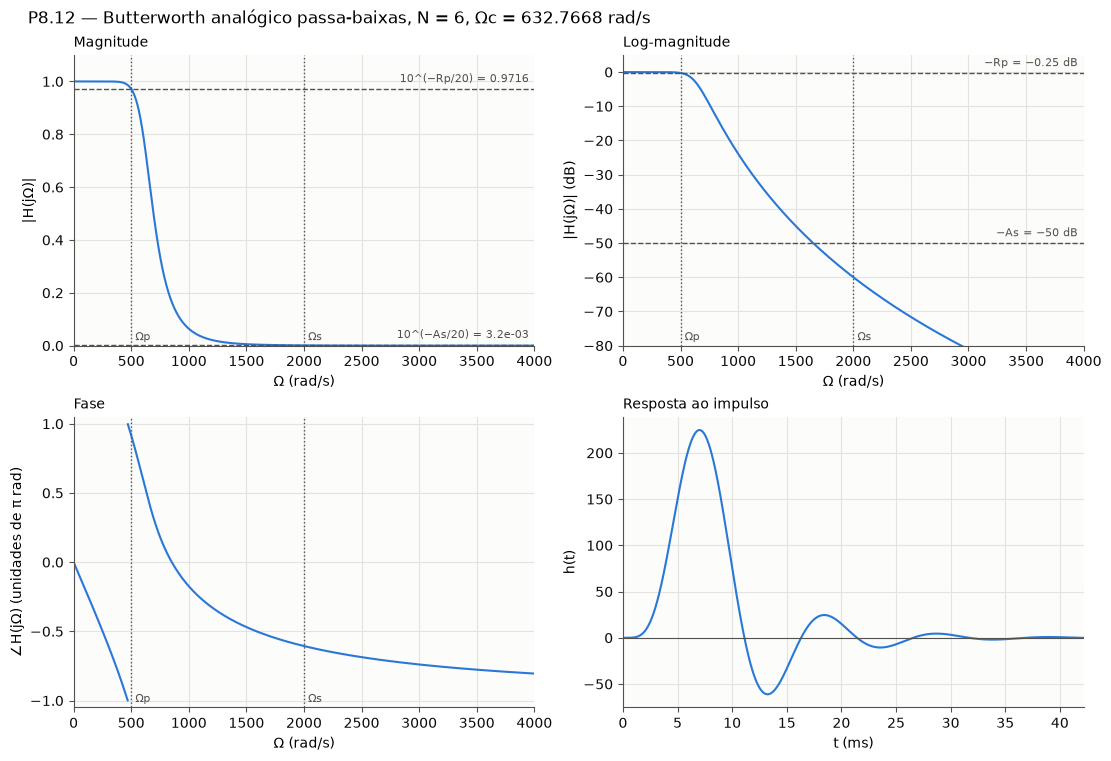

In [2]:
from content import p8_12 as content_mod
objs = content_mod.objects()
import matplotlib.pyplot as plt
from exercises import p8_12
fig = p8_12.plot(objs['proto'])
plt.show()

## 8. Gráficos e interpretação

### Polos no plano $s$


6 polos sobre o círculo de raio $\Omega_c = 632.8$ rad/s, espaçados de 30°. Os mais próximos do eixo $j\Omega$ (a $\pm105°$) definem a oscilação da resposta ao impulso.


### Magnitude


Plana até perto de $\Omega_p$ e decrescendo sem ondulações. Em $\Omega_p$ a magnitude vale exatamente $10^{-R_p/20}$.


### Magnitude em dB


Perda de 0.25 dB em $\Omega_p$ e atenuação de 59.97 dB em $\Omega_s$: 10.0 dB de folga, gerada pelo arredondamento de $N = 5.17$ para 6.


### Fase


Fase principal em $(-\pi, \pi]$. A fase total decresce até $-6\pi/2$. O salto é só a volta por $-\pi$.


### Resposta ao impulso


Oscilação amortecida: sobe, ultrapassa o eixo e decai. O amortecimento vem da parte real dos polos, e a oscilação, da parte imaginária do par mais próximo do eixo $j\Omega$.

## 9. Verificação das especificações


Três critérios: perda máxima em $[0, \Omega_p]$ ≤ $R_p$; atenuação mínima em $[\Omega_s, 100\,\Omega_s]$ ≥ $A_s$; e o mesmo projeto com $N - 1$ não alcança $A_s$ (minimalidade). Perdas medidas em relação a $|H_a(j0)| = 1$.

In [3]:
rep = objs.get('final_report') or objs.get('report')
print(rep)

Validação P8.12
  [OK  ] Perda máx. na passagem [dB]: 0.2500 <= 0.2500  (folga +0.0000)
  [OK  ] Atenuação mín. na rejeição [dB]: 59.9744 >= 50.0000  (folga +9.9744)
  [OK  ] Atenuação em Ωs com N−1 = 5 [dB] (deve falhar): 47.9332 <= 50.0000  (folga +2.0668)
  Resultado: ATENDE à especificação


## 10. Conclusão técnica


- **$N = 6$** ($\lceil 5.17 \rceil$) e **$\Omega_c = 632.7668$ rad/s**.
- $H_a(s) = B/A(s)$ com $B = a_0 = \Omega_c^{6} = 6.418923\times10^{16}$ e todos os coeficientes de $A(s)$ positivos. Os coeficientes coincidem com os do DTA.
- Perda de 0.25 dB em $\Omega_p$ (igual ao limite, por construção) e 59.97 dB em $\Omega_s$. Com $N = 5$ seriam 47.93 dB, insuficiente.